<p style="text-align:center">
    <a href="https://www.ict.mahidol.ac.th/en/" target="_blank">
    <img src="https://www3.ict.mahidol.ac.th/ICTSurveysV2/Content/image/MUICT2.png" width="400" alt="Faculty of ICT">
    </a>
</p>

# ITGE275: Economics
## Session 11: Wealth and Markets – Capital Markets and Dividends
**Topic:** Capital Market, Dividends, Profit Speculation, Saving Options, and Risk-Return Tradeoff.

---
### 👦 Student Information 👧

**Your name:** Qimin Zhu
**ID:** 6888143

---

### **1. Introduction: The Capital Market**

In previous sessions, we looked at how goods and services are traded. Today, we look at how **Capital (Money)** is traded. The **Capital Market** is where suppliers of capital (savers/investors) provide long-term funds to those who need it (companies/governments).

There are two main instruments to raise capital:
1.  **Debt (Bonds):** You lend money to a company/government. They promise to pay you back with a fixed interest rate. (Lower Risk, Lower Return).
2.  **Equity (Stocks):** You buy a piece of ownership in a company. Your return depends on the company's profits. (Higher Risk, Higher Return).

**How do Stocks make money?**
* **Dividends:** The company shares a portion of its actual profits directly with you (the shareholder) as cash.
* **Capital Gains:** Buying a stock at a low price and selling it at a higher price (Profit Speculation).

In this session, we will use Python to pull real-time data from the **Stock Exchange of Thailand (SET)**, visualize market movements using Candlestick charts, and calculate the mathematical trade-off between Risk and Return.

In [1]:
# Step 1: Import Libraries
# If you do not have yfinance or mplfinance installed, uncomment the line below and run it first:
!pip install yfinance mplfinance

  Using cached charset_normalizer-3.5.2-cp314-cp314-macosx_10_15_universal2.whl.metadata (46 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 7.4 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 4.2 MB/s  0:00:02 eta 0:00:01
Using cached idna-3.20-py3-none-any.whl (69 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18/18 [yfinance]/18 [mplfinance]


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation, rc
import yfinance as yf
import mplfinance as mpf
import warnings

warnings.filterwarnings('ignore')
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries loaded successfully.")

Libraries loaded successfully.


### **2. Fetching Market Data: The SET Index Case Study**

We will use the `yfinance` library to pull historical data for Thai stocks. Thai stocks on Yahoo Finance typically have a `.BK` suffix (standing for Bangkok).

Let's pull data for **PTT Public Company Limited (PTT.BK)**, one of the largest energy companies in Thailand.

Data for PTT.BK fetched successfully. Total trading days: 968


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2020-01-02 00:00:00+07:00,29.976730,30.823530,29.807370,30.823530,59084700,0.0,0.0
2020-01-03 00:00:00+07:00,31.331613,31.839693,31.162253,31.500973,147370600,0.0,0.0
2020-01-06 00:00:00+07:00,32.009049,32.347769,31.500969,31.839689,91026800,0.0,0.0
2020-01-07 00:00:00+07:00,32.009048,32.009048,31.331608,32.009048,60059600,0.0,0.0
2020-01-08 00:00:00+07:00,32.178414,32.347774,31.670334,31.670334,57759900,0.0,0.0


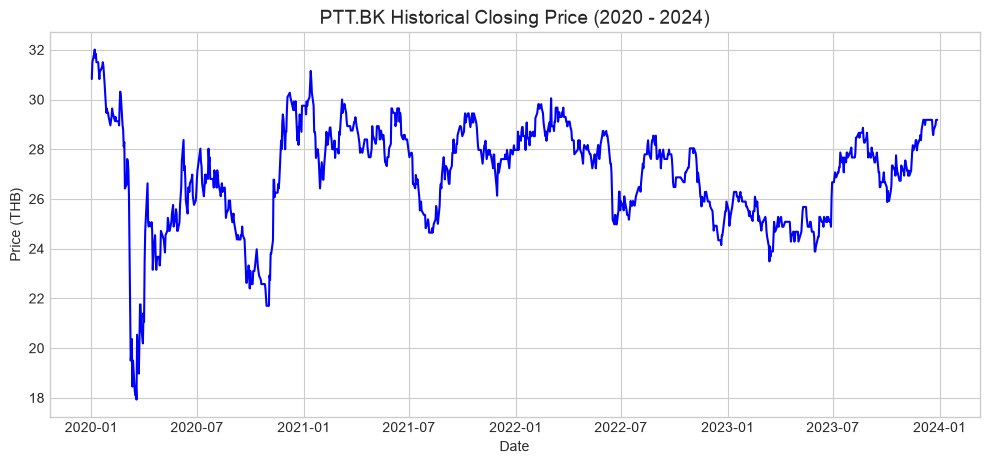

In [ ]:
# Define the ticker symbol
ticker_symbol = 'PTT.BK'

# Create a Ticker object
ptt = yf.Ticker(ticker_symbol)

# Fetch historical market data from 2020 to 2024
# Using .history() returns a clean, single-level DataFrame perfectly formatted for our analysis
df_ptt = ptt.history(start='2020-01-01', end='2024-01-01')

print(f"Data for {ticker_symbol} fetched successfully. Total trading days: {len(df_ptt)}")
display(df_ptt.head())

# Simple Line Plot of the Closing Price
plt.figure(figsize=(12, 5))
plt.plot(df_ptt.index, df_ptt['Close'], color='blue', linewidth=1.5)
plt.title('PTT.BK Historical Closing Price (2020 - 2024)', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Price (THB)')
plt.grid(True)
plt.show()

### **3. Market Visualization: Candlestick Charts**

Professional traders and speculators do not just look at a single line. They use **Candlestick Charts**.
A single "candle" represents one day of trading and shows 4 critical data points:
1.  **Open:** The price when the market opens.
2.  **High:** The highest price reached during the day.
3.  **Low:** The lowest price reached during the day.
4.  **Close:** The price when the market closes.

* **Green/White Candle:** Close > Open (Price went UP during the day).
* **Red/Black Candle:** Close < Open (Price went DOWN during the day).

We will use the `mplfinance` library to plot the last 60 trading days of PTT.

findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight

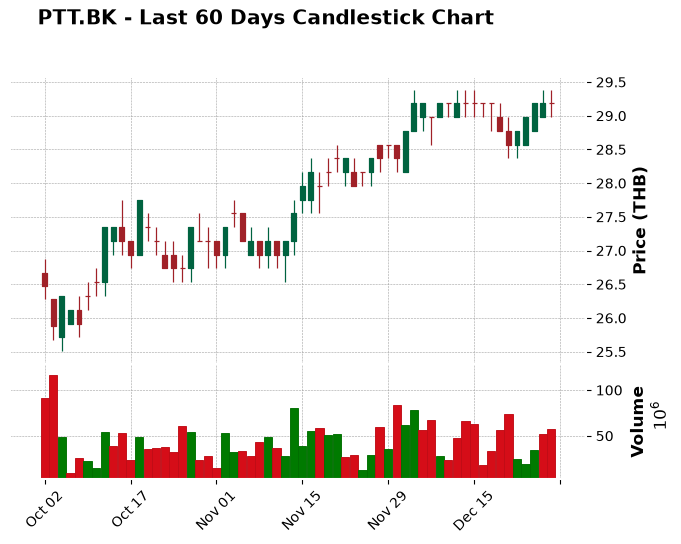

Notice the 'wicks' (thin lines) showing the intraday highs and lows, and the 'body' (thick box) showing the open-to-close shift.


In [4]:
# Slice the last 60 days of data
df_recent = df_ptt.tail(60)

# Plot using mplfinance
# type='candle' generates the candlestick chart
# volume=True adds a bar chart at the bottom showing trading volume (how many shares were traded)
mpf.plot(df_recent, 
         type='candle', 
         volume=True, 
         style='charles', 
         title='PTT.BK - Last 60 Days Candlestick Chart',
         ylabel='Price (THB)',
         ylabel_lower='Volume')

print("Notice the 'wicks' (thin lines) showing the intraday highs and lows, and the 'body' (thick box) showing the open-to-close shift.")

### **4. Risk and Return: The Mathematical Trade-off**

A core principle of Capital Markets is the **Risk-Return Tradeoff**: To potentially earn higher returns, you must accept a higher risk of losing money.

In Data Science and Finance, we quantify these as:
* **Return:** The mean (average) of the daily percentage changes in price.
* **Risk (Volatility):** The **Standard Deviation** of the daily percentage changes. A high standard deviation means the price swings wildly up and down.

Let's calculate the Annualized Return and Volatility for PTT.

--- PTT.BK Performance Metrics (2020-2023) ---
Annualized Expected Return: 3.36%
Annualized Volatility (Risk): 30.52%


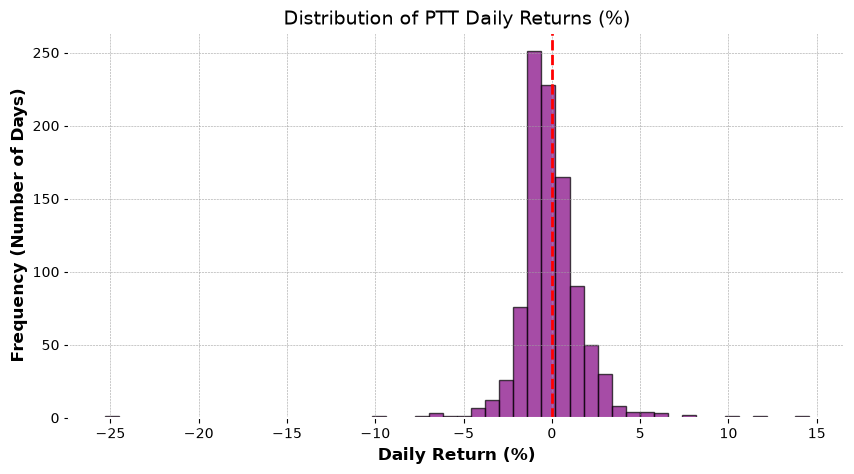

The wider this bell curve is, the higher the Risk (Volatility). A narrow curve means predictable, stable prices.


In [5]:
# 1. Calculate Daily Percentage Return
# .pct_change() calculates (Price_Today - Price_Yesterday) / Price_Yesterday
df_ptt['Daily_Return'] = df_ptt['Close'].pct_change()

# Drop the first NaN value
daily_returns = df_ptt['Daily_Return'].dropna()

# 2. Calculate Annualized Metrics
# There are generally 252 trading days in a year
annual_return = daily_returns.mean() * 252
annual_volatility = daily_returns.std() * np.sqrt(252)

print(f"--- PTT.BK Performance Metrics (2020-2023) ---")
print(f"Annualized Expected Return: {annual_return * 100:.2f}%")
print(f"Annualized Volatility (Risk): {annual_volatility * 100:.2f}%")

# 3. Visualize the Distribution of Returns
plt.figure(figsize=(10, 5))
plt.hist(daily_returns * 100, bins=50, color='purple', alpha=0.7, edgecolor='black')
plt.title('Distribution of PTT Daily Returns (%)', fontsize=14)
plt.xlabel('Daily Return (%)')
plt.ylabel('Frequency (Number of Days)')
plt.axvline(0, color='red', linestyle='dashed', linewidth=2)
plt.show()

print("The wider this bell curve is, the higher the Risk (Volatility). A narrow curve means predictable, stable prices.")

### **5. Comparing Saving Options (Risk vs. Return Plot)**

Let's compare the Risk-Return profile of different assets:
1.  **Savings Account:** ~1% return, near 0% risk.
2.  **Government Bonds:** ~3% return, very low risk.
3.  **Blue-Chip Stock (PTT):** Moderate return, moderate risk.
4.  **Growth Stock / High Volatility:** High expected return, massive risk.

We will fetch a few different stocks and plot them on a scatter plot to visualize the Efficient Market Frontier concept.

Calculating Risk/Return for multiple assets...


findfont: Failed to find font weight medium, now using 400.


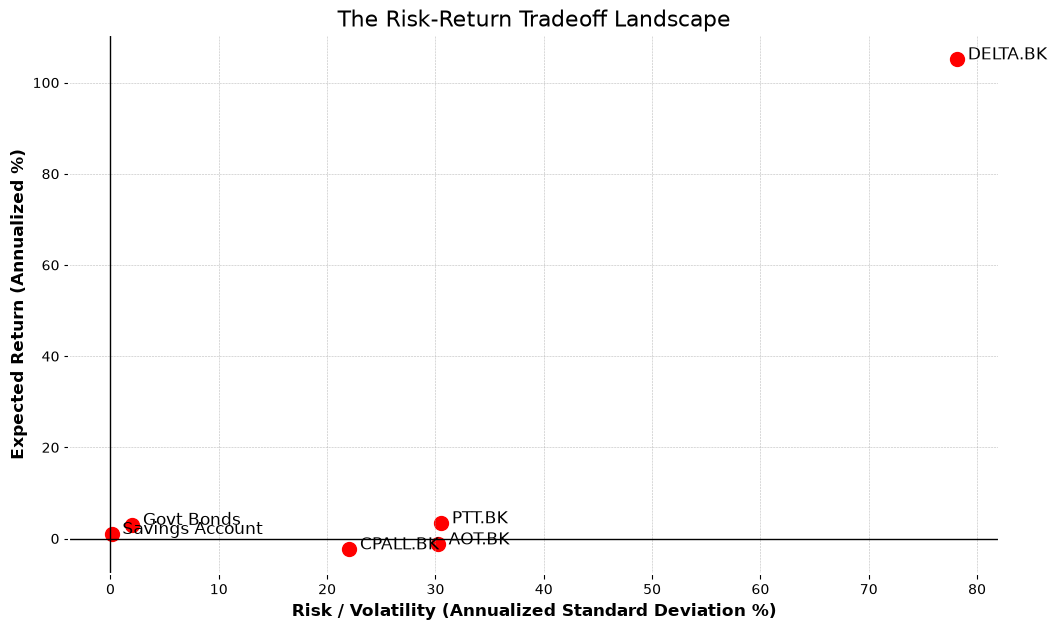

Notice the general upward slope: To get higher expected returns, you MUST move to the right (take on higher volatility/risk).


In [6]:
# Define a list of assets (including a proxy for bonds/cash)
assets = ['PTT.BK', 'CPALL.BK', 'AOT.BK', 'DELTA.BK']
returns_list = []
risks_list = []

print("Calculating Risk/Return for multiple assets...")
for ticker in assets:
    data = yf.Ticker(ticker).history(start='2020-01-01', end='2024-01-01')
    ret = data['Close'].pct_change().dropna()
    ann_ret = ret.mean() * 252 * 100
    ann_risk = ret.std() * np.sqrt(252) * 100
    returns_list.append(ann_ret)
    risks_list.append(ann_risk)

# Add safe assets manually for comparison
assets.extend(['Savings Account', 'Govt Bonds'])
returns_list.extend([1.0, 3.0])
risks_list.extend([0.1, 2.0])

# Scatter Plot: Risk vs Return
plt.figure(figsize=(12, 7))
plt.scatter(risks_list, returns_list, color='red', s=100)

# Annotate points
for i, txt in enumerate(assets):
    plt.annotate(txt, (risks_list[i] + 1, returns_list[i]), fontsize=12)

plt.title('The Risk-Return Tradeoff Landscape', fontsize=16)
plt.xlabel('Risk / Volatility (Annualized Standard Deviation %)', fontsize=12)
plt.ylabel('Expected Return (Annualized %)', fontsize=12)
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

print("Notice the general upward slope: To get higher expected returns, you MUST move to the right (take on higher volatility/risk).")

### **6. Dividends: The Real Profit Sharing**

Speculation focuses entirely on the price graph going up (Capital Gains). **Value Investing** focuses on buying fundamentally strong companies that generate actual cash flow and return it to owners via **Dividends**.

Let's look at the cash PTT has returned to its shareholders.

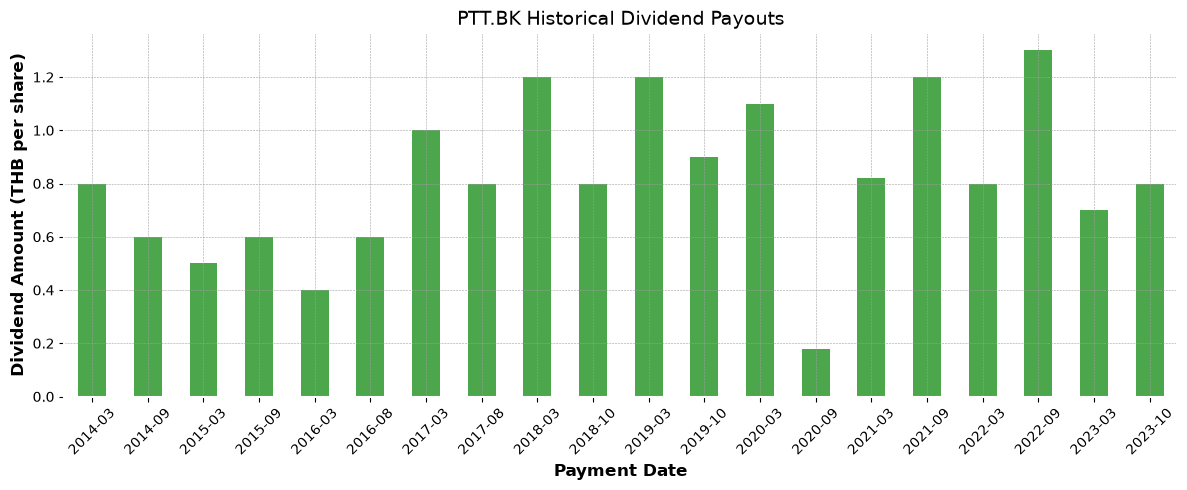

Even if the stock price goes nowhere, a value investor receives these cash payments just for holding the stock.


In [7]:
# Fetch Dividend History using the Ticker object created earlier
divs = ptt.dividends

# Filter for the last 10 years
divs_recent = divs.loc['2014-01-01':'2024-01-01']

plt.figure(figsize=(12, 5))
divs_recent.plot(kind='bar', color='green', alpha=0.7)
plt.title('PTT.BK Historical Dividend Payouts', fontsize=14)
plt.xlabel('Payment Date')
plt.ylabel('Dividend Amount (THB per share)')

# Formatting the x-axis dates to be readable
formatted_dates = [date.strftime('%Y-%m') for date in divs_recent.index]
plt.xticks(range(len(formatted_dates)), formatted_dates, rotation=45)
plt.tight_layout()
plt.show()

print("Even if the stock price goes nowhere, a value investor receives these cash payments just for holding the stock.")

### **7. Animation: Experiencing Volatility**

Looking at a static graph is easy. But *living* through market volatility tests investor psychology. Let's animate a stock's price to simulate what it feels like to watch your wealth fluctuate.

In [8]:
# === Animation: Simulating Market Volatility ===
fig, ax = plt.subplots(figsize=(10, 5))
plt.close() # Prevent double rendering in Jupyter

# We will animate a highly volatile stock: DELTA.BK
data_ani = yf.Ticker('DELTA.BK').history(start='2020-01-01', end='2021-01-01')['Close'].values
days_ani = np.arange(len(data_ani))

line, = ax.plot([], [], lw=2, color='orange')
ax.set_xlim(0, len(days_ani))
ax.set_ylim(min(data_ani)*0.9, max(data_ani)*1.1)
ax.set_title('Simulating 1 Year of Volatility (DELTA.BK in 2020)', fontsize=14)
ax.set_xlabel('Trading Days')
ax.set_ylabel('Price (THB)')
ax.grid(True)

def init():
    line.set_data([], [])
    return line,

def animate(i):
    # Plot data up to the current frame 'i'
    x = days_ani[:i]
    y = data_ani[:i]
    line.set_data(x, y)
    return line,

# Create animation (skip frames to make it run faster, e.g., frames=np.arange(0, len(days_ani), 5))
anim = animation.FuncAnimation(fig, animate, init_func=init, frames=np.arange(0, len(days_ani), 5), interval=100, blit=True)

# Display the animation using JSHTML
rc('animation', html='jshtml')
anim

---
## **8. Homework Assignment**

**Objective:** Apply your understanding of Market Structures, Risk/Return, and Capital Allocation.

#### **Question 1: Data Analysis - Risk Assessment**
1.  Modify the Python code from Section 4 to fetch data for **Siam Cement Group (SCC.BK)** from `2015-01-01` to `2023-01-01`.
2.  Calculate its Annualized Return and Annualized Volatility.
3.  Compare these metrics to the ones we calculated for **PTT.BK**. Based on the standard deviation (Volatility), which stock is mathematically "Riskier"?

#### **Question 2: Application - Daily Situation Allocation**
Imagine you have **100,000 THB** in cash today.
* **Goal A:** You need exactly **50,000 THB** in 6 months to pay for your university tuition. 
* **Goal B:** You want to save the remaining **50,000 THB** for your retirement in 30 years.

Using the concepts of the **Risk-Return Tradeoff** and **Volatility**, explain how you would allocate the money for Goal A versus Goal B among the three primary Saving Options: Savings Accounts, Government Bonds, and Stocks (Equity). Provide economic reasoning for your choices.

*(Write your answers in the Markdown cell below)*

Data for SCC.BK fetched successfully. Total trading days: 1944


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2015-01-05 00:00:00+07:00,306.484545,306.484545,301.083936,303.784241,1020300,0.0,0.0
2015-01-06 00:00:00+07:00,301.083972,301.083972,292.983058,298.383667,2115900,0.0,0.0
2015-01-07 00:00:00+07:00,295.683362,298.383667,294.333210,298.383667,2041500,0.0,0.0
2015-01-08 00:00:00+07:00,301.083960,305.134417,299.733808,302.434113,1209700,0.0,0.0
2015-01-09 00:00:00+07:00,305.134436,306.484589,303.784284,306.484589,545500,0.0,0.0


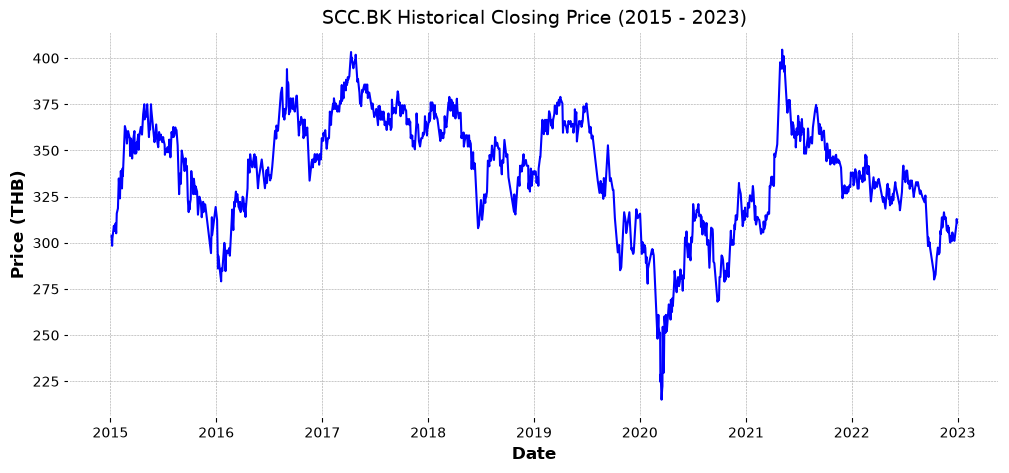

--- SCC.BK Performance Metrics (2015-2023) ---
Annualized Expected Return: 2.52%
Annualized Volatility (Risk): 21.06%


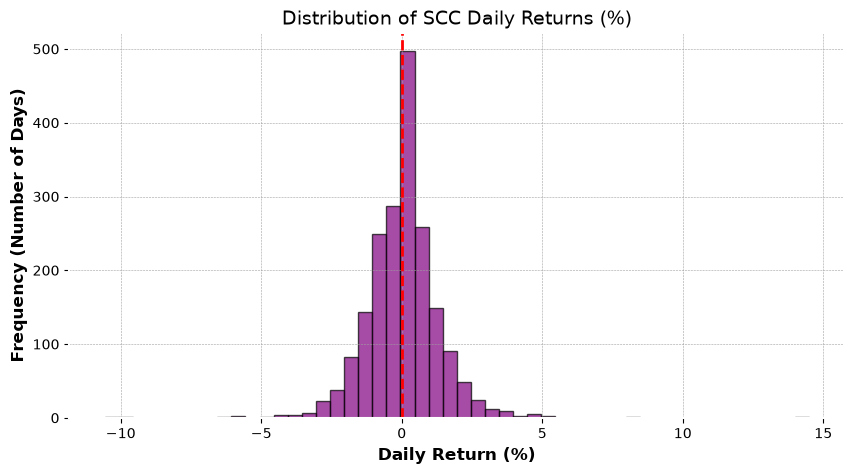

The wider this bell curve is, the higher the Risk (Volatility). A narrow curve means predictable, stable prices.


In [11]:
# === HOMEWORK SPACE: QUESTION 1 ===
# Write your code here to calculate SCC.BK volatility
# Define the ticker symbol
ticker_symbol = 'SCC.BK'

# Create a Ticker object
scc = yf.Ticker(ticker_symbol)

# Fetch historical market data from 2020 to 2024
# Using .history() returns a clean, single-level DataFrame perfectly formatted for our analysis
df_scc = scc.history(start='2015-01-01', end='2023-01-01')

print(f"Data for {ticker_symbol} fetched successfully. Total trading days: {len(df_scc)}")
display(df_scc.head())

# Simple Line Plot of the Closing Price
plt.figure(figsize=(12, 5))
plt.plot(df_scc.index, df_scc['Close'], color='blue', linewidth=1.5)
plt.title('SCC.BK Historical Closing Price (2015 - 2023)', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Price (THB)')
plt.grid(True)
plt.show()


# 1. Calculate Daily Percentage Return
# .pct_change() calculates (Price_Today - Price_Yesterday) / Price_Yesterday
df_scc['Daily_Return'] = df_scc['Close'].pct_change()

# Drop the first NaN value
daily_returns = df_scc['Daily_Return'].dropna()

# 2. Calculate Annualized Metrics
# There are generally 252 trading days in a year
annual_return = daily_returns.mean() * 252
annual_volatility = daily_returns.std() * np.sqrt(252)

print(f"--- SCC.BK Performance Metrics (2015-2023) ---")
print(f"Annualized Expected Return: {annual_return * 100:.2f}%")
print(f"Annualized Volatility (Risk): {annual_volatility * 100:.2f}%")

# 3. Visualize the Distribution of Returns
plt.figure(figsize=(10, 5))
plt.hist(daily_returns * 100, bins=50, color='purple', alpha=0.7, edgecolor='black')
plt.title('Distribution of SCC Daily Returns (%)', fontsize=14)

plt.xlabel('Daily Return (%)')
plt.ylabel('Frequency (Number of Days)')
plt.axvline(0, color='red', linestyle='dashed', linewidth=2)
plt.show()

print("The wider this bell curve is, the higher the Risk (Volatility). A narrow curve means predictable, stable prices.")

### **Student Answers Space**

**Q1 Answer:**
The Volatility of SCC.BK is ... 
Compared to PTT, it is [More/Less] risky because...

Based on the Distribution of Daily Returns graph, the PTT has a slightly left skew graph compare to SCC. So that, I can conclude that SCC is slightly lesser risky than PTT.

**Q2 Answer:**
* **Goal A (Tuition in 6 months):** I would put this money in... because...

I would put this money in savings, because it will be used in a 6 months, and also it is a mandatory expense, keep it in savings is lesser risky than other options.

* **Goal B (Retirement in 30 years):** I would put this money in... because...

I would put this money in goverment bond and stock market, because one I want to balance the total riskiness of my account, the bond will give me less return and less riskiness, whereas, the stock could provide a higher return and higher riskiness. Based on above, I will also make sure that the investment in the stock market is long-term, to reduce its affect to my daily life(I will less care about the short-term fluctuation).
